# Zomato Restaurant Intelligence: EDA, Sentiment Analysis & Unsupervised ML

**Project Type:** Data Science / Unsupervised Machine Learning / NLP baseline  
**Contribution:** Individual  
**Dataset:** Zomato restaurant metadata (105 rows) and customer reviews (10,000 rows)

---

## Project Summary

This project analyzes restaurant metadata and customer reviews to investigate restaurant attributes, customer feedback, cuisine and cost patterns, and discover restaurant segments using unsupervised machine learning. The analysis joins the two datasets by normalized restaurant name, explores data quality and distributions, derives restaurant-level review and sentiment features, and compares clustering approaches. A lightweight lexicon sentiment baseline is used for exploratory sentiment analysis; it is not a validated production sentiment model. Clusters are interpreted descriptively and recommendations are framed as exploratory insights rather than causal conclusions.

## GitHub Link

_Add repository URL after publishing._

## Problem Statement

Restaurants and platforms need a structured way to understand restaurant offerings, customer experience, affordability, and patterns across restaurants. This project explores the supplied Zomato data, summarizes customer reviews, and segments restaurants based on selected numeric features. Because the data contains only 105 restaurant records and reviews are associated with a subset, conclusions are limited to this sample and cannot be generalized to all Zomato restaurants.

## 1. Know Your Data

In [1]:
import os, re, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
DATA_DIR = os.path.join('..', 'data') if os.path.basename(os.getcwd()) == 'notebooks' else 'data'
metadata_path = os.path.join(DATA_DIR, 'restaurant_metadata.csv')
reviews_path = os.path.join(DATA_DIR, 'restaurant_reviews.csv')
metadata = pd.read_csv(metadata_path)
reviews = pd.read_csv(reviews_path)
print('Metadata shape:', metadata.shape)
print('Reviews shape:', reviews.shape)

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-1gwimwu5 because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Metadata shape: (105, 6)
Reviews shape: (10000, 7)


### Dataset Loading and First View

In [2]:
display(metadata.head())
display(reviews.head())

,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


### Rows, Columns, Information and Duplicate Checks

In [3]:
print('Metadata rows/columns:', metadata.shape)
print('Review rows/columns:', reviews.shape)
metadata.info()
reviews.info()
print('Metadata duplicate rows:', metadata.duplicated().sum())
print('Review duplicate rows:', reviews.duplicated().sum())
print('Metadata missing values:\n', metadata.isna().sum())
print('Review missing values:\n', reviews.isna().sum())

Metadata rows/columns: (105, 6)
Review rows/columns: (10000, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 5   Timings      104 non-null    object
dtypes: object(6)
memory usage: 5.1+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  int6

### Dataset Overview and Limitations

The restaurant table contains name, URL, cost, collections, cuisines and timings. The reviews table contains restaurant name, reviewer, review text, rating, reviewer metadata, timestamp and picture count. The tables are joined by normalized restaurant names; unmatched records are retained in the review dataset for review-level analysis but cannot contribute to joined restaurant-level profiles.

## 2. Understanding Your Variables

In [4]:
metadata.describe(include='all').T


,count,unique,top,freq
Name,105,105,Beyond Flavours,1
Links,105,105,https://www.zomato.com/hyderabad/beyond-flavou...,1
Cost,105,29,500,13
Collections,51,42,Food Hygiene Rated Restaurants in Hyderabad,4
Cuisines,105,92,"North Indian, Chinese",4
Timings,104,77,11 AM to 11 PM,6


In [5]:
reviews.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Restaurant,10000,100,Beyond Flavours,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reviewer,9962,7446,Ankita,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review,9955,9364,good,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9962,10,5,3832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metadata,9962,2477,1 Review,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9962,9782,7/29/2018 20:34,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pictures,10000.0,NaN,NaN,NaN,0.7486,2.570381,0.0,0.0,0.0,0.0,64.0


### Unique Values and Data Dictionary

In [6]:
for col in metadata.columns:
    print(f'{col}: {metadata[col].nunique(dropna=True)} unique values')
for col in reviews.columns:
    print(f'{col}: {reviews[col].nunique(dropna=True)} unique values')

Name: 105 unique values
Links: 105 unique values
Cost: 29 unique values
Collections: 42 unique values
Cuisines: 92 unique values
Timings: 77 unique values
Restaurant: 100 unique values
Reviewer: 7446 unique values
Review: 9364 unique values
Rating: 10 unique values
Metadata: 2477 unique values
Time: 9782 unique values
Pictures: 36 unique values


## 3. Data Wrangling and Cleaning

In [7]:
# Keep copies; normalize restaurant names for join keys
meta = metadata.copy()
rev = reviews.copy()
def normalize_name(value):
    if pd.isna(value): return ''
    value = str(value).lower().strip()
    value = re.sub(r'[^a-z0-9]+', ' ', value)
    return re.sub(r'\\s+', ' ', value).strip()
meta['restaurant_key'] = meta['Name'].map(normalize_name)
rev['restaurant_key'] = rev['Restaurant'].map(normalize_name)
# Remove duplicate restaurant metadata rows based on normalized name
meta = meta.drop_duplicates('restaurant_key').copy()
# Numeric conversions
meta['Cost_numeric'] = pd.to_numeric(meta['Cost'].astype(str).str.replace(',', '', regex=False), errors='coerce')
rev['Rating_numeric'] = pd.to_numeric(rev['Rating'], errors='coerce')
rev['Pictures_numeric'] = pd.to_numeric(rev['Pictures'], errors='coerce')
rev['Review_text'] = rev['Review'].fillna('').astype(str)
rev['Time_parsed'] = pd.to_datetime(rev['Time'], errors='coerce')
# Matching diagnostics
matched_keys = set(meta.restaurant_key) & set(rev.restaurant_key)
print('Unique metadata restaurants:', meta.restaurant_key.nunique())
print('Unique review restaurant keys:', rev.restaurant_key.nunique())
print('Matched restaurant names:', len(matched_keys))
print('Unmatched metadata names:', len(set(meta.restaurant_key)-set(rev.restaurant_key)))
print('Unmatched review keys:', len(set(rev.restaurant_key)-set(meta.restaurant_key)))
print('Ratings parseable:', rev.Rating_numeric.notna().sum())

Unique metadata restaurants: 105
Unique review restaurant keys: 100
Matched restaurant names: 100
Unmatched metadata names: 5
Unmatched review keys: 0
Ratings parseable: 9961


### Exploratory Text Sentiment Baseline

For reproducibility and avoiding external downloads, this notebook uses a simple positive/negative word lexicon as a transparent baseline. It does not capture sarcasm, context, negation reliably, or domain-specific nuance. Sentiment labels should be treated as exploratory, not ground truth.

In [8]:
positive_words = set('good great excellent amazing awesome delicious tasty fresh perfect lovely wonderful nice best enjoyable recommend friendly helpful prompt clean beautiful satisfied love loved'.split())
negative_words = set('bad poor terrible awful worst disappointing tasteless stale rude slow dirty overpriced horrible hate hated unhappy disappointing'.split())
def sentiment_score(text):
    tokens = re.findall(r'[a-z]+', str(text).lower())
    pos = sum(t in positive_words for t in tokens)
    neg = sum(t in negative_words for t in tokens)
    return pos-neg
rev['sentiment_score'] = rev['Review_text'].map(sentiment_score)
rev['sentiment'] = np.select([rev.sentiment_score>0, rev.sentiment_score<0], ['Positive','Negative'], default='Neutral')
rev['rating_bucket'] = np.select([rev.Rating_numeric>=4, rev.Rating_numeric<=2], ['High rating','Low rating'], default='Mid rating')
print(rev.sentiment.value_counts())
display(rev[['Restaurant','Rating','sentiment_score','sentiment']].head())

sentiment
Positive    7116
Neutral     1973
Negative     911
Name: count, dtype: int64


,Restaurant,Rating,sentiment_score,sentiment
0,Beyond Flavours,5,4,Positive
1,Beyond Flavours,5,4,Positive
2,Beyond Flavours,5,3,Positive
3,Beyond Flavours,5,2,Positive
4,Beyond Flavours,5,3,Positive


### Create Restaurant-level Review Features and Joined Dataset

In [9]:
review_agg = rev.groupby('restaurant_key').agg(
    review_count=('Review_text','size'),
    average_rating=('Rating_numeric','mean'),
    rating_median=('Rating_numeric','median'),
    rating_std=('Rating_numeric','std'),
    positive_share=('sentiment', lambda s: (s=='Positive').mean()),
    negative_share=('sentiment', lambda s: (s=='Negative').mean()),
    neutral_share=('sentiment', lambda s: (s=='Neutral').mean()),
    average_sentiment_score=('sentiment_score','mean'),
    average_pictures=('Pictures_numeric','mean'),
    last_review=('Time_parsed','max')
).reset_index()
joined = meta.merge(review_agg, on='restaurant_key', how='left')
joined['cuisine_count'] = joined['Cuisines'].fillna('').apply(lambda s: len([x for x in str(s).split(',') if x.strip()]))
joined['collection_count'] = joined['Collections'].fillna('').apply(lambda s: len([x for x in str(s).split(',') if x.strip()]))
joined['cost_per_cuisine'] = joined['Cost_numeric'] / joined['cuisine_count'].replace(0,np.nan)
print('Joined profile shape:', joined.shape)
display(joined.head())

Joined profile shape: (105, 21)


,Name,Links,Cost,Collections,Cuisines,Timings,restaurant_key,Cost_numeric,review_count,average_rating,rating_median,rating_std,positive_share,negative_share,neutral_share,average_sentiment_score,average_pictures,last_review,cuisine_count,collection_count,cost_per_cuisine
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",beyond flavours,800,100.0,4.28,5.0,1.239746,0.86,0.07,0.07,2.68,0.39,2019-05-25 15:54:00,6,6,133.333333
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM,paradise,800,100.0,4.70,5.0,0.771984,0.95,0.03,0.02,3.50,0.02,2019-05-25 16:50:00,3,1,266.666667
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM",flechazo,1300,100.0,4.66,5.0,0.878704,0.99,0.00,0.01,2.99,0.55,2019-05-24 21:17:00,4,2,325.000000
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM,shah ghouse hotel restaurant,800,100.0,3.21,4.0,1.603626,0.71,0.12,0.17,1.08,0.30,2019-05-25 18:32:00,5,1,160.000000
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no...",over the moon brew company,1200,100.0,4.34,5.0,1.065719,0.91,0.07,0.02,2.93,0.44,2019-05-24 22:22:00,5,5,240.000000


### What manipulations were performed?

- Normalized restaurant names for join keys.
- Removed duplicate metadata rows by normalized name.
- Converted cost, rating and picture count to numeric values.
- Parsed timestamps.
- Scored review text with a simple lexicon baseline.
- Aggregated reviews to restaurant-level metrics.
- Created cuisine/collection counts and cost-per-cuisine as exploratory features.

## 4. Data Visualization, Storytelling and Experiments

### Chart 1 — Restaurant cost distribution

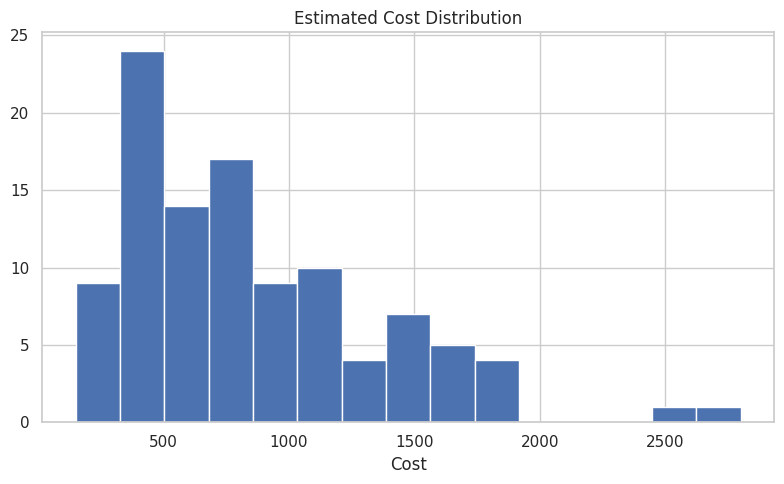

In [10]:
plt.figure(figsize=(8,5)); plt.hist(joined['Cost_numeric'].dropna(), bins=15); plt.title('Estimated Cost Distribution'); plt.xlabel('Cost'); plt.tight_layout(); plt.savefig('../outputs/cost_distribution.png', dpi=150); plt.show()

The cost distribution helps characterize affordability. The histogram may be skewed, so the median and distribution shape should be considered alongside the mean.

### Chart 2 — Cuisine counts

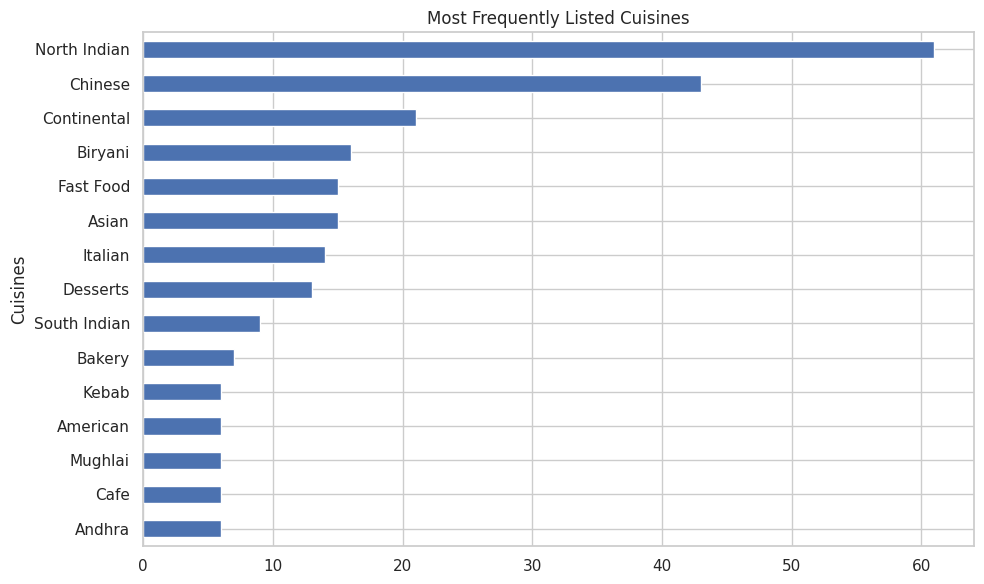

Cuisines
North Indian    61
Chinese         43
Continental     21
Biryani         16
Asian           15
Fast Food       15
Italian         14
Desserts        13
South Indian     9
Bakery           7
Mughlai          6
Kebab            6
Andhra           6
Cafe             6
American         6
Name: count, dtype: int64

In [11]:
cuisines = meta['Cuisines'].fillna('').str.split(',').explode().str.strip()
cuisines = cuisines[cuisines!='']
top_cuisines = cuisines.value_counts().head(15)
plt.figure(figsize=(10,6)); top_cuisines.sort_values().plot(kind='barh'); plt.title('Most Frequently Listed Cuisines'); plt.tight_layout(); plt.savefig('../outputs/top_cuisines.png', dpi=150); plt.show()
display(top_cuisines)

### Chart 3 — Restaurant average rating distribution

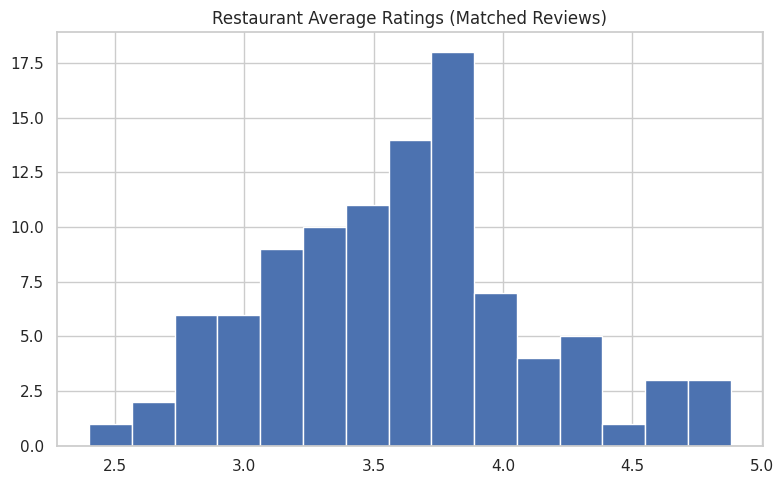

In [12]:
plt.figure(figsize=(8,5)); plt.hist(joined['average_rating'].dropna(), bins=15); plt.title('Restaurant Average Ratings (Matched Reviews)'); plt.tight_layout(); plt.savefig('../outputs/average_rating_distribution.png', dpi=150); plt.show()

### Chart 4 — Cost vs Average Rating

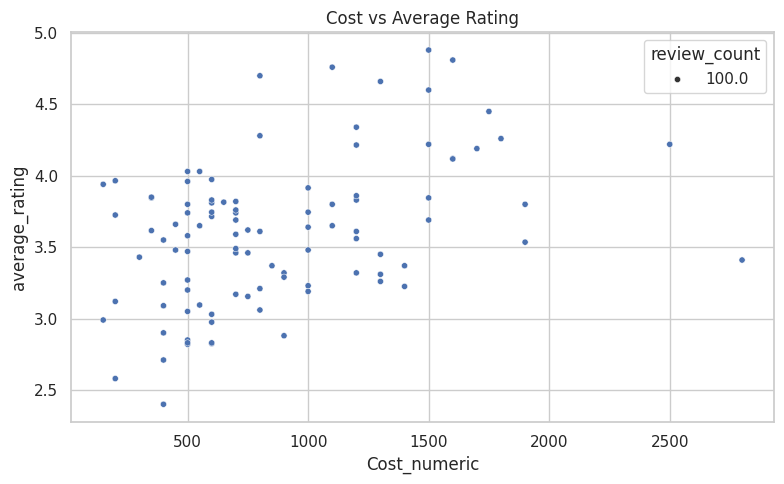

In [13]:
plt.figure(figsize=(8,5)); sns.scatterplot(data=joined, x='Cost_numeric', y='average_rating', size='review_count', sizes=(20,150)); plt.title('Cost vs Average Rating'); plt.tight_layout(); plt.savefig('../outputs/cost_vs_rating.png', dpi=150); plt.show()

### Chart 5 — Review sentiment distribution

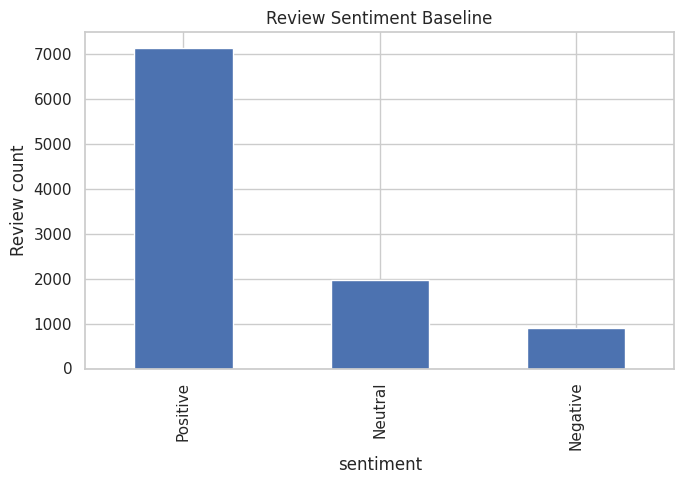

In [14]:
plt.figure(figsize=(7,5)); rev.sentiment.value_counts().reindex(['Positive','Neutral','Negative']).plot(kind='bar'); plt.title('Review Sentiment Baseline'); plt.ylabel('Review count'); plt.tight_layout(); plt.savefig('../outputs/sentiment_distribution.png', dpi=150); plt.show()

### Chart 6 — Rating and sentiment comparison

sentiment
Positive    4.158117
Neutral     2.638243
Negative    1.295280
Name: Rating_numeric, dtype: float64

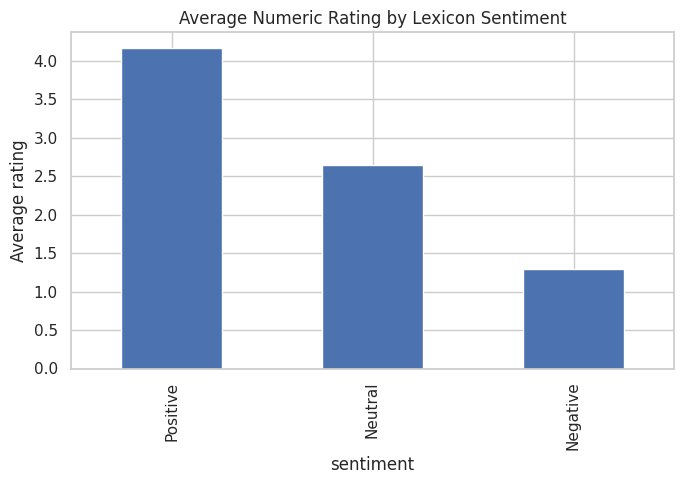

In [15]:
sent_rating = rev.groupby('sentiment')['Rating_numeric'].mean().reindex(['Positive','Neutral','Negative'])
display(sent_rating)
plt.figure(figsize=(7,5)); sent_rating.plot(kind='bar'); plt.title('Average Numeric Rating by Lexicon Sentiment'); plt.ylabel('Average rating'); plt.tight_layout(); plt.savefig('../outputs/sentiment_rating_comparison.png', dpi=150); plt.show()

### Chart 7 — Review counts by restaurant

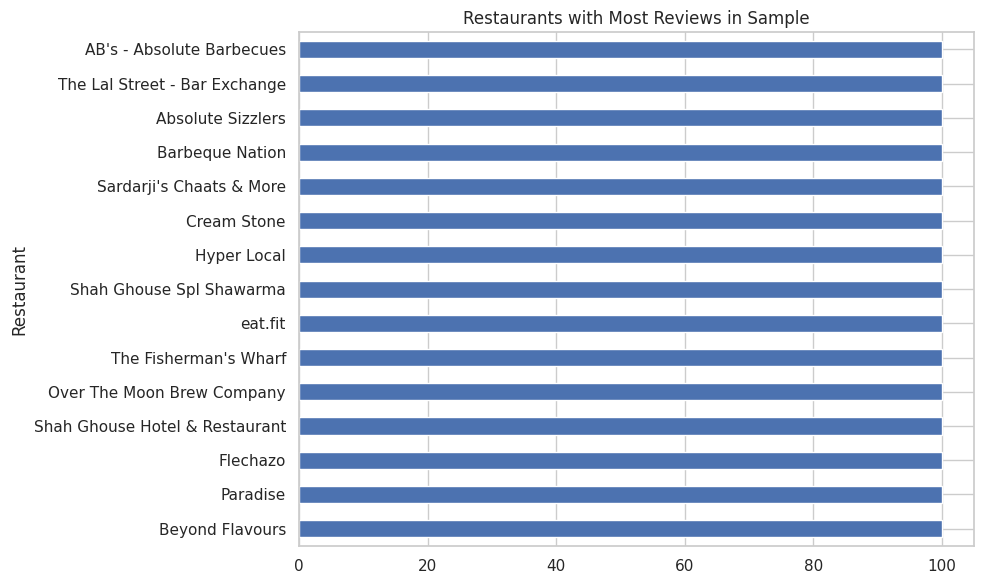

In [16]:
top_reviewed = rev.Restaurant.value_counts().head(15)
plt.figure(figsize=(10,6)); top_reviewed.sort_values().plot(kind='barh'); plt.title('Restaurants with Most Reviews in Sample'); plt.tight_layout(); plt.savefig('../outputs/top_reviewed_restaurants.png', dpi=150); plt.show()

### Chart 8 — Cluster profiles (generated after modeling)

### Chart 9 — PCA cluster visualization (generated after modeling)

### Chart 10 — Cuisine count vs average rating

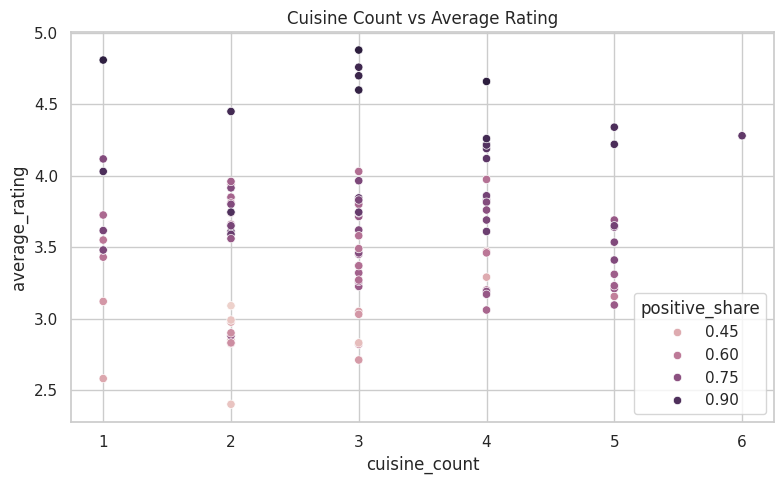

In [17]:
plt.figure(figsize=(8,5)); sns.scatterplot(data=joined, x='cuisine_count', y='average_rating', hue='positive_share'); plt.title('Cuisine Count vs Average Rating'); plt.tight_layout(); plt.savefig('../outputs/cuisine_count_rating.png', dpi=150); plt.show()

### Chart 11 — Review volume and negative share

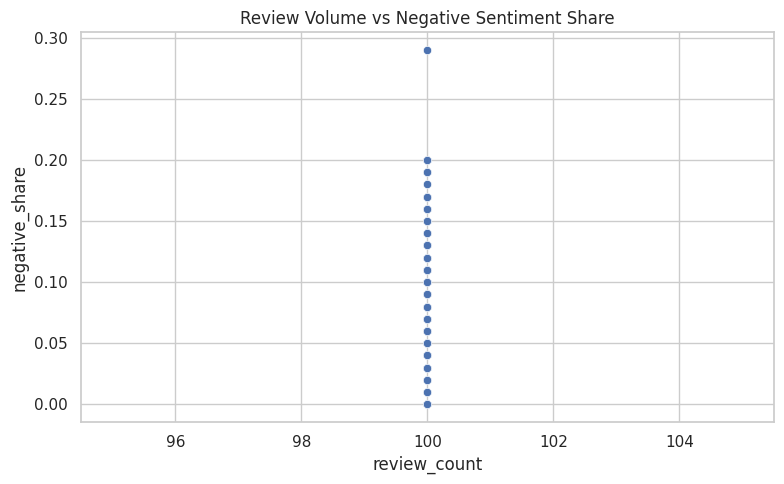

In [18]:
plt.figure(figsize=(8,5)); sns.scatterplot(data=joined, x='review_count', y='negative_share'); plt.title('Review Volume vs Negative Sentiment Share'); plt.tight_layout(); plt.savefig('../outputs/review_volume_negative_share.png', dpi=150); plt.show()

### Chart 12 — Cost by cuisine count

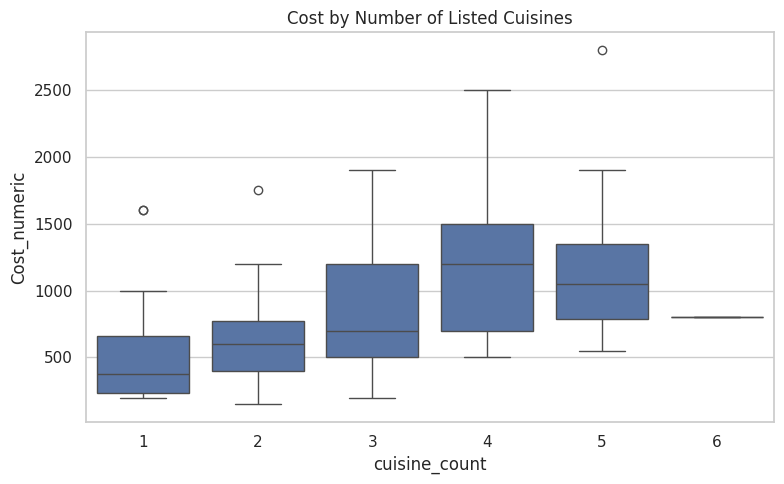

In [19]:
plt.figure(figsize=(8,5)); sns.boxplot(data=joined, x='cuisine_count', y='Cost_numeric'); plt.title('Cost by Number of Listed Cuisines'); plt.tight_layout(); plt.savefig('../outputs/cost_by_cuisine_count.png', dpi=150); plt.show()

### Chart 13 — Rating variability

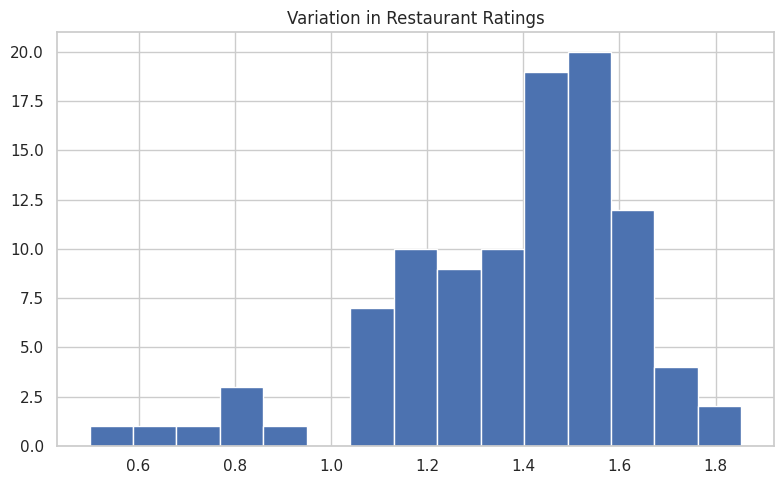

In [20]:
plt.figure(figsize=(8,5)); plt.hist(joined['rating_std'].dropna(), bins=15); plt.title('Variation in Restaurant Ratings'); plt.tight_layout(); plt.savefig('../outputs/rating_variability.png', dpi=150); plt.show()

### Correlation Heatmap

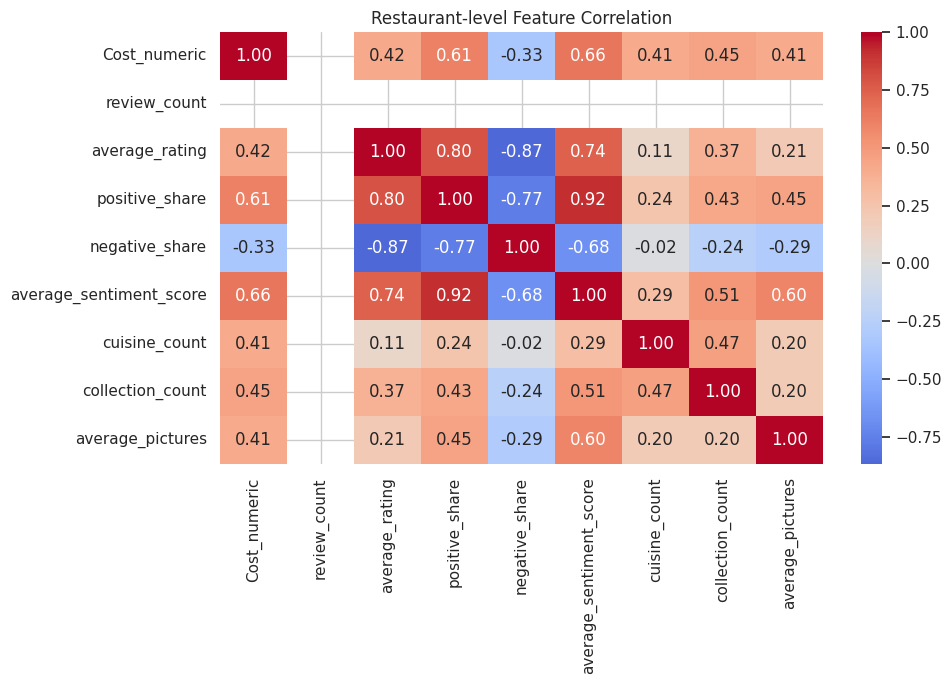

In [21]:
corr_features = ['Cost_numeric','review_count','average_rating','positive_share','negative_share','average_sentiment_score','cuisine_count','collection_count','average_pictures']
correlation = joined[corr_features].corr(numeric_only=True)
plt.figure(figsize=(10,7)); sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.title('Restaurant-level Feature Correlation'); plt.tight_layout(); plt.savefig('../outputs/correlation_heatmap.png', dpi=150); plt.show()

### Pair Plot

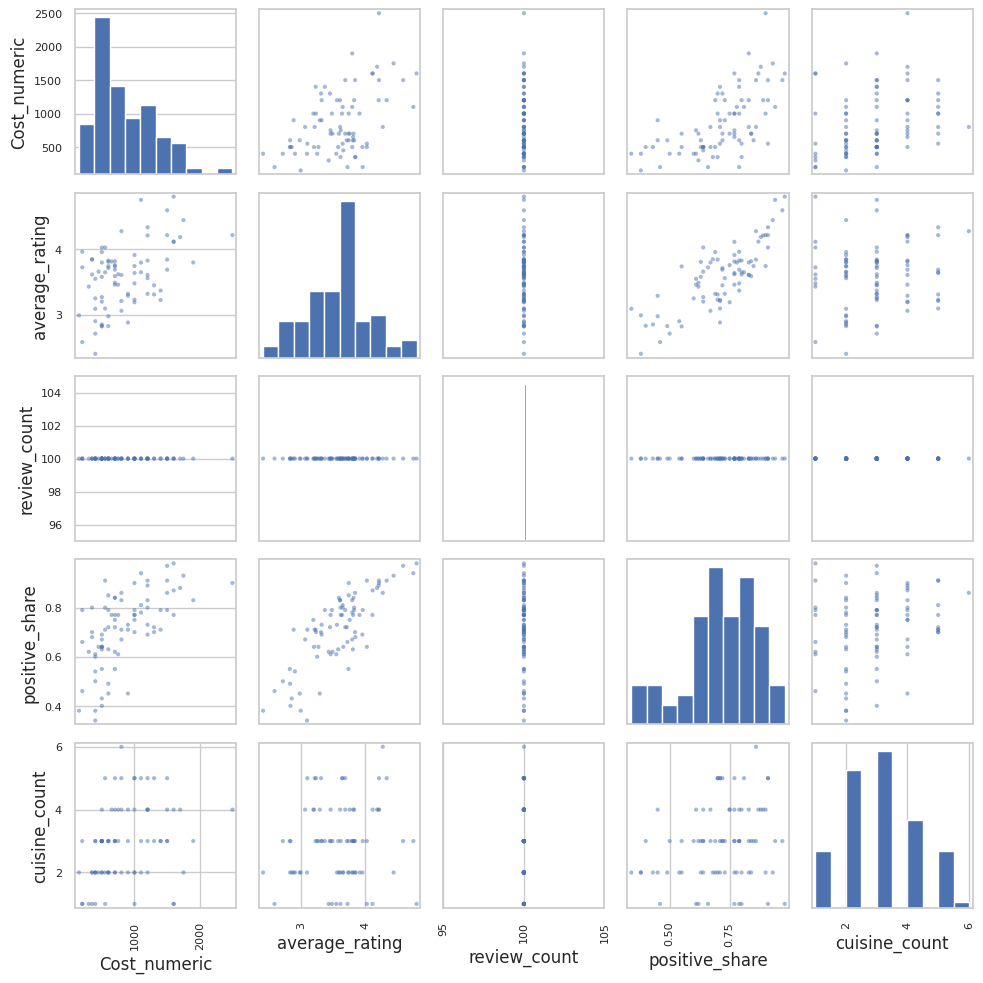

In [22]:
from pandas.plotting import scatter_matrix
pair_cols = ['Cost_numeric','average_rating','review_count','positive_share','cuisine_count']
pair_data = joined[pair_cols].dropna()
if len(pair_data)>1:
    scatter_matrix(pair_data.sample(min(len(pair_data),80), random_state=RANDOM_STATE), figsize=(10,10), diagonal='hist'); plt.tight_layout(); plt.savefig('../outputs/pairplot.png', dpi=150); plt.show()

## 5. Hypothesis Testing

The tests are exploratory and use the joined restaurant-level sample. The sample size is small and the lexicon sentiment labels are noisy; p-values should not be interpreted as causal evidence.

### Hypothesis 1 — Restaurant cost and average rating

**H0:** There is no monotonic association between restaurant estimated cost and average rating.  
**H1:** There is a monotonic association.

In [23]:
h1_data = joined[['Cost_numeric','average_rating']].dropna()
h1_stat, h1_p = stats.spearmanr(h1_data['Cost_numeric'], h1_data['average_rating']) if len(h1_data)>=3 else (np.nan,np.nan)
print('Spearman correlation:', h1_stat, 'p-value:', h1_p, 'n:', len(h1_data))

Spearman correlation: 0.38261181045369264 p-value: 8.544462215836537e-05 n: 100


**Test:** Spearman rank correlation. It is suitable for assessing monotonic association without requiring normal distributions.

### Hypothesis 2 — Review sentiment and rating

**H0:** Numeric ratings do not differ across lexicon sentiment groups.  
**H1:** At least one sentiment group has a different rating distribution.

In [24]:
h2_groups = [g['Rating_numeric'].dropna().values for _,g in rev.groupby('sentiment')]
h2_groups = [g for g in h2_groups if len(g)>0]
h2_stat, h2_p = stats.kruskal(*h2_groups) if len(h2_groups)>=2 else (np.nan,np.nan)
print('Kruskal-Wallis statistic:', h2_stat, 'p-value:', h2_p, 'group sizes:', [len(g) for g in h2_groups])

Kruskal-Wallis statistic: 3189.9388965076146 p-value: 0.0 group sizes: [911, 1935, 7115]


**Test:** Kruskal-Wallis test, a non-parametric comparison across multiple groups.

### Hypothesis 3 — Review count and positive sentiment share

**H0:** Restaurant review count is not associated with positive sentiment share.  
**H1:** There is a monotonic association.

In [25]:
h3_data = joined[['review_count','positive_share']].dropna()
h3_stat, h3_p = stats.spearmanr(h3_data['review_count'], h3_data['positive_share']) if len(h3_data)>=3 else (np.nan,np.nan)
print('Spearman correlation:', h3_stat, 'p-value:', h3_p, 'n:', len(h3_data))

Spearman correlation: nan p-value: nan n: 100


## 6. Feature Engineering and Pre-processing

### Missing values

In [26]:
print(joined.isna().sum().sort_values(ascending=False))
# Clustering feature preparation: keep features with usable coverage and impute medians.
cluster_features = ['Cost_numeric','average_rating','review_count','positive_share','negative_share','average_sentiment_score','cuisine_count','collection_count','average_pictures']
X_raw = joined[cluster_features].copy()
print('Selected features:', cluster_features)

Collections                54
average_rating              5
rating_median               5
rating_std                  5
review_count                5
last_review                 5
average_pictures            5
neutral_share               5
negative_share              5
positive_share              5
average_sentiment_score     5
Timings                     1
Name                        0
Cuisines                    0
Cost                        0
Links                       0
Cost_numeric                0
restaurant_key              0
cuisine_count               0
collection_count            0
cost_per_cuisine            0
dtype: int64
Selected features: ['Cost_numeric', 'average_rating', 'review_count', 'positive_share', 'negative_share', 'average_sentiment_score', 'cuisine_count', 'collection_count', 'average_pictures']


### Outliers

In [27]:
# Visual inspection and IQR flags for numeric features; no rows are automatically removed for clustering.
outlier_summary = {}
for col in ['Cost_numeric','review_count','average_rating']:
    s=joined[col].dropna()
    if len(s):
        q1,q3=s.quantile([.25,.75]); iqr=q3-q1
        outlier_summary[col]=int(((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).sum())
print('IQR outlier counts (flags only):', outlier_summary)

IQR outlier counts (flags only): {'Cost_numeric': 2, 'review_count': 0, 'average_rating': 3}


### Encoding, transformation and scaling

Text categorical fields such as cuisines and collections are represented here using counts rather than one-hot encoding of high-cardinality text. Numeric features are standardized before distance-based clustering. Missing values are median-imputed. Cost and review volume may be skewed; this notebook compares a log-transformed variant in future extensions, but the baseline uses standardized raw values.

### Text preprocessing

For the lexicon baseline, reviews are lowercased and tokenized into alphabetic words internally. A full NLP pipeline (contraction expansion, stemming/lemmatization, POS tagging, TF-IDF or transformer embeddings) is not required for this baseline and is a recommended extension.

### Feature selection and dimensionality reduction

Selected clustering features are numeric and interpretable. PCA is used only for 2D visualization, not for fitting the final clustering. Feature selection is exploratory because the sample contains only about 100 matched restaurant profiles.

### Data splitting and class imbalance

Clustering is unsupervised and does not use a train/test split or target label. Sentiment classes are baseline labels, not a supervised target; no class balancing is applied.

## 7. ML Model Implementation — Clustering

### Model comparison: K-Means, Agglomerative, DBSCAN

,model,k,silhouette,davies_bouldin,inertia
0,KMeans k=2,2,0.301116,1.276379,540.097450
1,KMeans k=3,3,0.233335,1.411391,436.346906
2,KMeans k=4,4,0.241648,1.356561,369.446592
3,KMeans k=5,5,0.250917,1.349121,317.524279
4,KMeans k=6,6,0.256467,1.281310,281.438966


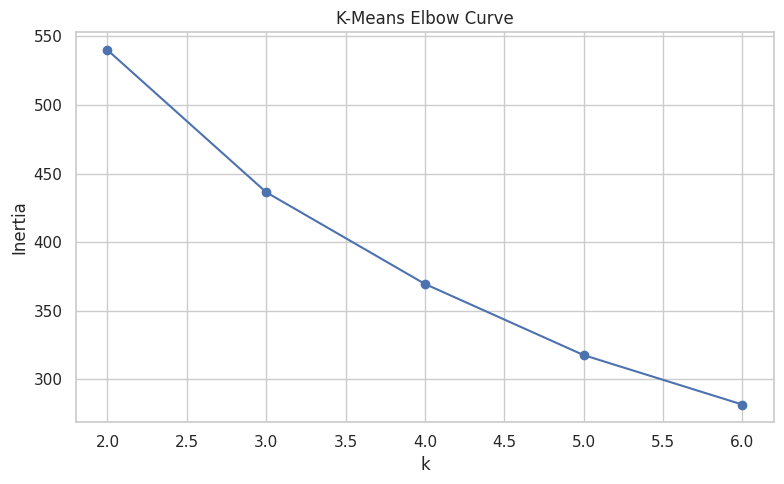

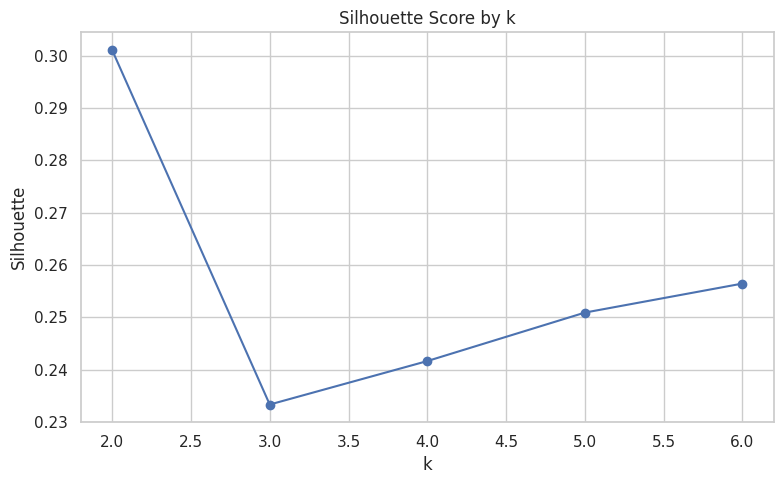

In [28]:
# Prepare matrix with median imputation and standard scaling
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X_raw)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
# Try K-Means k=2..6 (within sample size)
k_results=[]
for k in range(2, min(7, len(joined))):
    km=KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels=km.fit_predict(X_scaled)
    k_results.append({'model':f'KMeans k={k}','k':k,'silhouette':silhouette_score(X_scaled,labels),'davies_bouldin':davies_bouldin_score(X_scaled,labels),'inertia':km.inertia_})
k_results_df=pd.DataFrame(k_results)
display(k_results_df)
plt.figure(figsize=(8,5)); plt.plot(k_results_df.k,k_results_df.inertia,marker='o'); plt.title('K-Means Elbow Curve'); plt.xlabel('k'); plt.ylabel('Inertia'); plt.tight_layout(); plt.savefig('../outputs/elbow_curve.png',dpi=150); plt.show()
plt.figure(figsize=(8,5)); plt.plot(k_results_df.k,k_results_df.silhouette,marker='o'); plt.title('Silhouette Score by k'); plt.xlabel('k'); plt.ylabel('Silhouette'); plt.tight_layout(); plt.savefig('../outputs/silhouette_by_k.png',dpi=150); plt.show()

### Select baseline K-Means and compare other algorithms

In [29]:
# Select k by silhouette score as an exploratory criterion
best_k=int(k_results_df.loc[k_results_df.silhouette.idxmax(),'k'])
final_kmeans=KMeans(n_clusters=best_k,random_state=RANDOM_STATE,n_init=20)
kmeans_labels=final_kmeans.fit_predict(X_scaled)
# Agglomerative clustering with same k
agg_labels=AgglomerativeClustering(n_clusters=best_k).fit_predict(X_scaled)
# DBSCAN with a conservative exploratory setting; may label many observations as noise
try:
    db_labels=DBSCAN(eps=1.2,min_samples=4).fit_predict(X_scaled)
except Exception:
    db_labels=np.full(len(joined),-1)
def clustering_metrics(name, labels):
    unique=set(labels); nonnoise=[x for x in unique if x!=-1]
    valid=(len(nonnoise)>=2 and len(set(labels))>=2 and len(labels)>len(set(labels)))
    sil=silhouette_score(X_scaled,labels) if valid else np.nan
    dbi=davies_bouldin_score(X_scaled,labels) if valid else np.nan
    return {'model':name,'clusters_including_noise':len(unique),'silhouette':sil,'davies_bouldin':dbi}
model_comparison=pd.DataFrame([clustering_metrics(f'KMeans k={best_k}',kmeans_labels),clustering_metrics(f'Agglomerative k={best_k}',agg_labels),clustering_metrics('DBSCAN eps=1.2 min_samples=4',db_labels)])
display(model_comparison)
joined['cluster']=kmeans_labels
print('Selected K-Means k:',best_k)

,model,clusters_including_noise,silhouette,davies_bouldin
0,KMeans k=2,2,0.301116,1.276379
1,Agglomerative k=2,2,0.328481,1.254017
2,DBSCAN eps=1.2 min_samples=4,4,0.018876,1.865206


Selected K-Means k: 2


### Cluster profiles and visualization

,restaurant_count
cluster,
0,63
1,42


,Cost_numeric,average_rating,review_count,positive_share,negative_share,average_sentiment_score,cuisine_count,collection_count,average_pictures
cluster,,,,,,,,,
0,588.889,3.337,100.0,0.619,0.118,1.145,2.730,0.444,0.434
1,1270.238,3.986,100.0,0.845,0.053,2.644,3.357,1.857,1.201


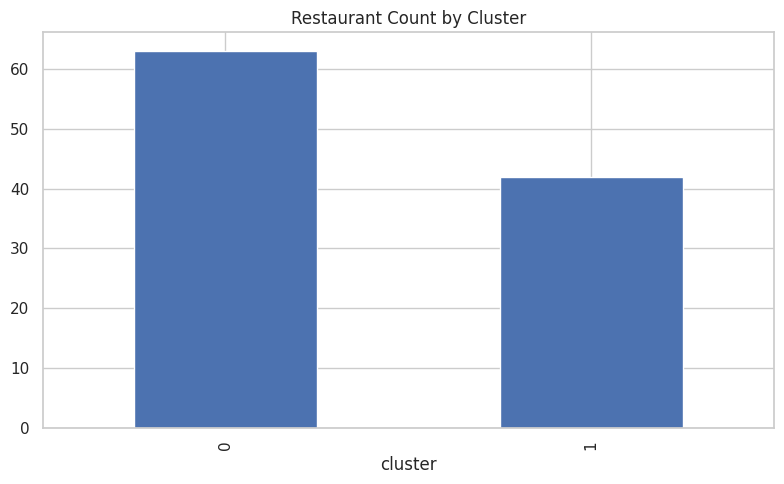

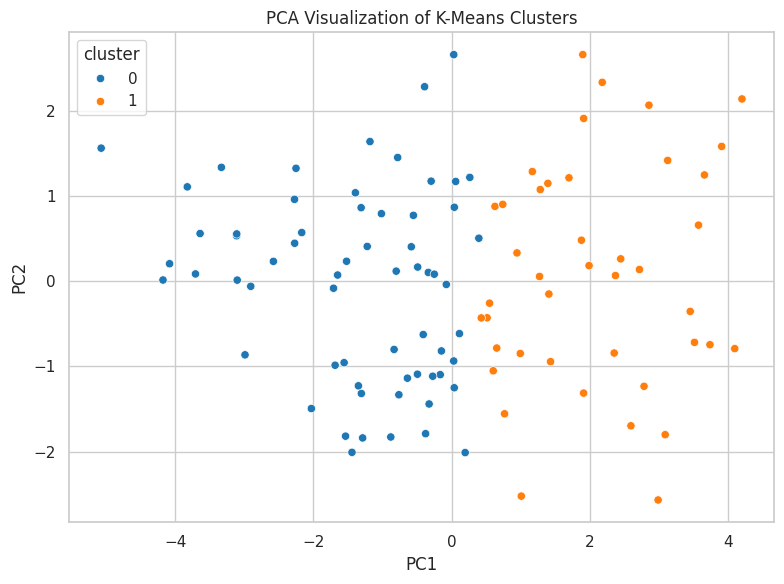

PCA explained variance ratio: [0.54466402 0.17671187]


In [30]:
profile=joined.groupby('cluster')[cluster_features].mean().round(3)
cluster_sizes=joined.cluster.value_counts().sort_index()
display(cluster_sizes.rename('restaurant_count').to_frame())
display(profile)
profile.to_csv('../outputs/cluster_profile.csv')
joined.to_csv('../outputs/restaurant_clusters.csv',index=False)
model_comparison.to_csv('../outputs/model_metrics.csv',index=False)
plt.figure(figsize=(8,5)); cluster_sizes.plot(kind='bar'); plt.title('Restaurant Count by Cluster'); plt.tight_layout(); plt.savefig('../outputs/cluster_counts.png',dpi=150); plt.show()
# PCA visualization
pca=PCA(n_components=2,random_state=RANDOM_STATE)
coords=pca.fit_transform(X_scaled)
plot_df=pd.DataFrame(coords,columns=['PC1','PC2']); plot_df['cluster']=kmeans_labels
plt.figure(figsize=(8,6)); sns.scatterplot(data=plot_df,x='PC1',y='PC2',hue='cluster',palette='tab10'); plt.title('PCA Visualization of K-Means Clusters'); plt.tight_layout(); plt.savefig('../outputs/pca_clusters.png',dpi=150); plt.show()
print('PCA explained variance ratio:',pca.explained_variance_ratio_)

### Model evaluation and selection

The silhouette score measures separation and cohesion (higher is generally better, bounded from -1 to 1); the Davies–Bouldin index measures similarity between clusters (lower is generally better). Neither metric alone establishes business usefulness. We use K-Means as the primary segmenting model because it is straightforward to profile, while reporting other algorithm results as comparison. Cluster labels are arbitrary identifiers.

### Cluster interpretation and business recommendations

Interpret each cluster using its profile table rather than assigning labels before seeing results. Consider cost, average rating, review volume, sentiment shares and cuisine/collection breadth. Cluster recommendations should be framed as hypotheses for business action and validated with more data.

## 8. Future Work

- Replace the lexicon sentiment baseline with a validated NLP classifier or transformer-based sentiment model.
- Collect larger and more geographically diverse restaurant data.
- Use more robust restaurant-name matching and verify unmatched records.
- Experiment with log transforms, feature weighting and alternative clustering algorithms.
- Validate cluster stability and business usefulness.
- Build an interactive dashboard and deploy.

## Conclusion

This project combines exploratory data analysis, review sentiment exploration and unsupervised restaurant segmentation. The data supports descriptive insights within the supplied sample, but limitations—including the small metadata sample, name-based matching, rating parsing and simple lexicon sentiment—mean findings should be treated as exploratory. The next iteration should validate sentiment labels, improve matching, test cluster stability and expand the dataset.